In [ ]:
# Code is taken from official paper notebook: 
# https://github.com/lmcinnes/umap_paper_notebooks/blob/master/CrossVal%20KNN%20Classifier%20-%20Pendigits.ipynb

In [26]:
import numpy as np
import pandas as pd
import sklearn.neighbors
import sklearn.model_selection
import sklearn.datasets
import sklearn.manifold
import sklearn.decomposition

In [27]:
def score_embedding(data, labels, k=10, n_neighbors=5, random_state=42):
    model = sklearn.neighbors.KNeighborsClassifier(n_neighbors=n_neighbors)
    cv = sklearn.model_selection.StratifiedKFold(n_splits=k)
    return sklearn.model_selection.cross_val_score(model, data, labels, cv=cv)

In [28]:
def compare_embeddings(embeddings, n_neighbors=5, k=10, random_state=42):
    cross_val_scores = {}
    for alg in embeddings.keys():
        cross_val_scores[alg] = score_embedding(embeddings[alg][['x', 'y']].values, 
                                                embeddings[alg]['labels'].values,
                                                n_neighbors=n_neighbors,
                                                k=k,
                                                random_state=random_state)
    return pd.DataFrame(cross_val_scores).assign(n_neighbors=n_neighbors)

In [29]:
digits = sklearn.datasets.load_digits()

pendigits = {}
pendigits['tsne'] = pd.read_csv('embedding_pendigits_tsne1.csv', index_col=0)
pendigits['umap'] = pd.read_csv('embedding_pendigits_umap1.csv', index_col=0)
pendigits['lvis'] = pd.read_csv('embedding_pendigits_largevis1.csv', index_col=0)
pendigits['fits'] = pd.read_csv('embedding_pendigits_fitsne1.csv', index_col=0)

pendigits['leig'] = pd.DataFrame(
    sklearn.manifold.SpectralEmbedding(n_components=2).fit_transform(digits.data), 
    columns=('x', 'y')).assign(labels=digits.target)
pendigits['pca'] = pd.DataFrame(
    sklearn.decomposition.PCA(n_components=2).fit_transform(digits.data), 
    columns=('x', 'y')).assign(labels=digits.target)

In [30]:
df = pd.concat(compare_embeddings(pendigits, n_neighbors=n) for n in (10,20,40,80,160))

In [31]:
df.groupby('n_neighbors', ).mean()

,tsne,umap,lvis,fits,leig,pca
n_neighbors,,,,,,
10,0.974410,0.972750,0.962185,0.969966,0.777405,0.621558
20,0.972179,0.974963,0.969398,0.971068,0.777967,0.631586
40,0.953849,0.952169,0.949392,0.957182,0.777952,0.634922
80,0.947163,0.950503,0.943827,0.949385,0.770161,0.646601
160,0.948274,0.950503,0.913228,0.948271,0.744578,0.631009


In [32]:
df.groupby('n_neighbors', ).std() * 2

,tsne,umap,lvis,fits,leig,pca
n_neighbors,,,,,,
10,0.036745,0.044255,0.064310,0.039254,0.116826,0.086990
20,0.037079,0.034465,0.051433,0.038453,0.122755,0.082402
40,0.078194,0.067312,0.077406,0.063702,0.116089,0.071094
80,0.080663,0.063801,0.081395,0.059814,0.109518,0.076798
160,0.077864,0.063801,0.085805,0.060185,0.115847,0.097927


In [22]:
import seaborn as sns
sns.set()

In [23]:
tidy_df = df.reset_index().melt(id_vars=['index', 'n_neighbors'], 
                                value_vars=['fits', 'leig', 'lvis', 'pca', 'tsne', 'umap'])
tidy_df = tidy_df.rename(columns={'index':'fold', 'variable':'algorithm'})
tidy_df = tidy_df[tidy_df.algorithm != 'fits']

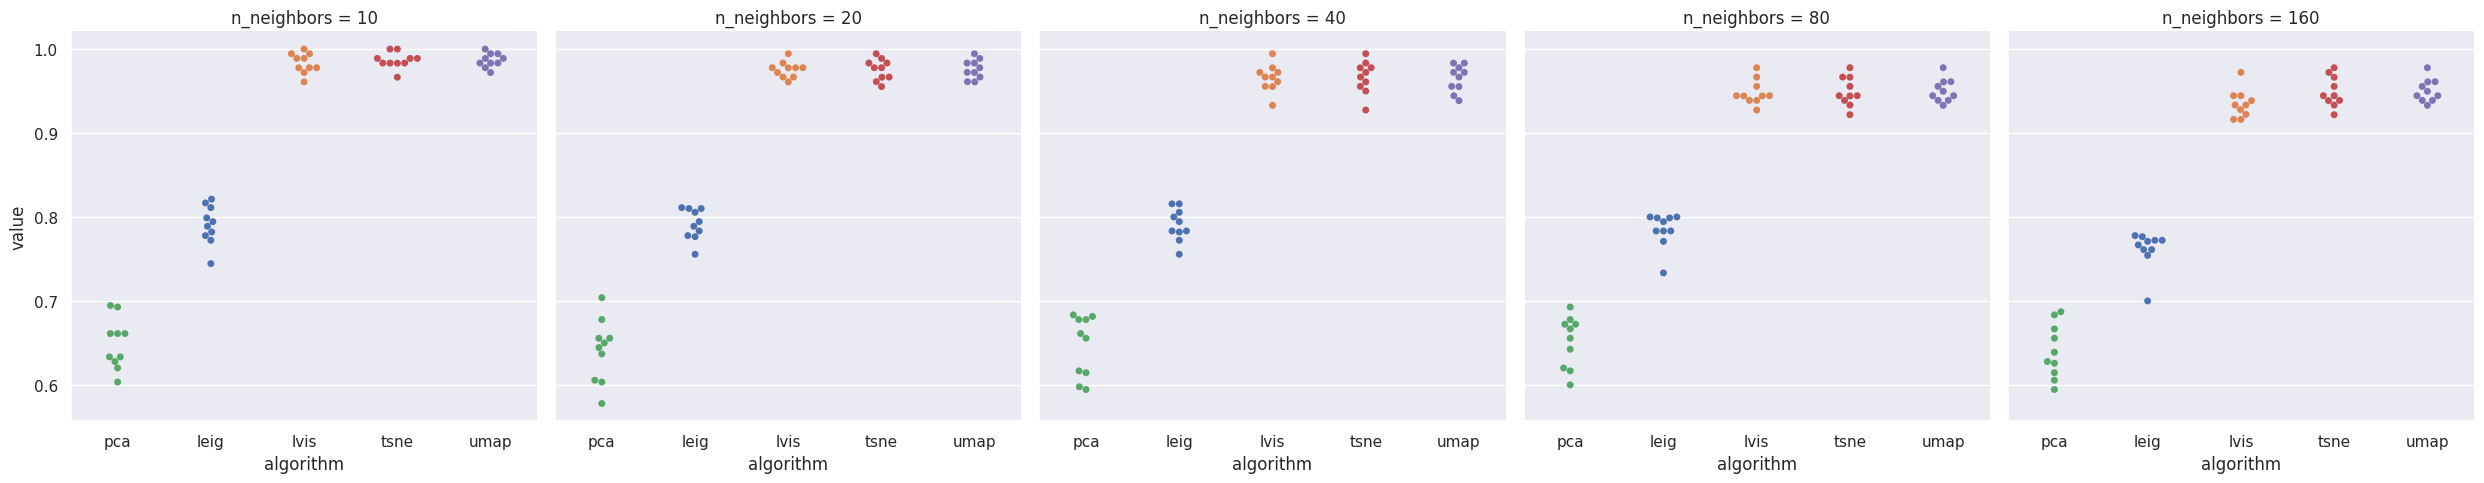

In [24]:
sns.catplot(x='algorithm', 
            y='value', 
            hue='algorithm', 
            kind='swarm', 
            col='n_neighbors',
            order=['pca', 'leig', 'lvis', 'tsne', 'umap'],
            data=tidy_df)

In [10]:
tidy_df.assign(dataset='PenDigits').to_csv('pendigits_crossval_results.csv')

NameError: name 'tidy_df' is not defined